# Second Programming Assignment

# Traffic Flow Analysis - Part 1 (Data)

---

Group Number: 15

Members:

1. Yueting Gou 03805239
2. Tiantian Xing 03805986

In this project, you will develop models to predict traffic flow in California, US. Such insights can help optimize traffic management, reduce congestion, and improve navigation systems for example. The task is divided into two parts:

1. **Decision Trees:** Predict traffic flow over the next hour as a categorical variable (low, average, high).
2. **Neural Networks:** Regression model to predict the exact traffic flow (over the next hour) as a continuous variable.

But before starting with that, you need to preprocess the data and perform some eda, which is the main goal of this notebook.

In [3]:
# Necessary imports

import json
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

## 1. Data Preprocessing

The traffic data for this project comes from the [Caltrans Performance Measurement System (PeMS)](https://pems.dot.ca.gov/). To be specific, we will use the data from District 3 (Sacramento and Marysville areas), collected over a duration of three months (September to November 2018). This is commonly refered to as the **PEMS03** dataset in literature.

While there are many Stations in the area, we'll focus on a set of 358 stations which are listed in the file `Station_IDs.txt`.

In [4]:
stn_ids = []
with open("/content/sample_data/Station_IDs.txt", "r") as f:
    for line in f:
        s = line.strip()
        if s:
            stn_ids.append(int(s))

stn_ids = sorted(stn_ids)

In [5]:
# Mapping of station IDs to indices (0-357), for easy access
# Use this in subsequent tasks

stn_mapping = dict()

for (i, stn_id) in enumerate(stn_ids):
    stn_mapping[stn_id] = i

Next up, let's get some metadata for these stations. The file `Station_Metadata.txt` contains the following information (tab separated):

* **ID:** Unique identifier
* **Fwy:** Freeway number (e.g. 5, 10, 405)
* **Dir:** Freeway direction (N | S | E | W)
* **District:** District number
* **County:** County number
* **City:** City number
* **State_PM:** Position of detector station using the California postmile system.
* **Abs_PM:** Absolute position of detector station.
* **Latitude:** Estimated latitude of detector station.
* **Longitude:** Estimated longitude of detector station.
* **Length:** Length of detection.

* **Type:** Type of station. For example:

    * ML = Mainline
    * FR = Off-ramp
    * OR = On-ramp
    * HV = High Occupancy Vehicle
    * CD = Coll/Dist
    * FF = Freeway-to-Freeway

* **Lanes:** Number of lanes.
* **Name:**	Name of station.
* **User_ID_[1-4]:** User defined strings.

**Note:** The file also contains metadata for stations that we don't consider. Also, take care of data types while loading the data.

In [6]:
stn_metadata = dict()

df = pd.read_csv("/content/sample_data/Station_Metadata.txt", sep="\t", dtype=str)
df.columns = [c.strip() for c in df.columns]

df["ID"] = df["ID"].astype(int)
df = df[df["ID"].isin(stn_ids)]

stn_metadata = {}
for _, row in df.iterrows():
    sid = int(row["ID"])
    i = stn_mapping[sid]
    stn_metadata[i] = {
        "ID": sid,
        "Fwy": row.get("Fwy", ""),
        "Dir": row.get("Dir", ""),
        "District": row.get("District", ""),
        "County": row.get("County", ""),
        "City": row.get("City", "")
    }

Moving on, we have geographical knowledge in form of a graph, with the stations as nodes. The file `Connections.csv` contains the edges. Entries in the adjacency matrix should be 0 or 1, depending on whether there is a connection between two stations or not. The distance matrix should contain the distance between stations. (∞ if no connection, 0 in diagonal)

**Note:** Both matrices should be symmetric, as the graph is undirected.

In [7]:
# 1. Create numpy arrays named adj_matrix and dist_matrix of shape (358, 358)

adj_matrix = np.zeros((358, 358), dtype=int)
dist_matrix = np.full((358,358), np.inf, dtype=np.float32)
dist_matrix[range(358), range(358)] = 0

edges = pd.read_csv("/content/sample_data/Connections.csv")

for _, row in edges.iterrows():
    sid1 = int(row["from"])
    sid2 = int(row["to"])
    d = float(row["distance"])

    if sid1 in stn_mapping and sid2 in stn_mapping:
        i = stn_mapping[sid1]
        j = stn_mapping[sid2]
        adj_matrix[i, j] = 1
        adj_matrix[j, i] = 1
        dist_matrix[i, j] = d
        dist_matrix[j, i] = d

Finally, the temporal data is stored in the file `PEMS03.txt`. There is a datapoint for each station every 1 hour. So we need to extract 24 hours * 91 days = 2184 readings for each station. Again, there's a lot of data in this file, but we only consider the following 3 important variables:

* **Flow:** Vehicle flow over the hour. (This is the target variable y)
* **Occupancy:** Station occupancy over the hour expressed as a decimal number between 0 and 1.
* **Avgerage Speed:** Of the passing vehicles.

Each line in the file is comma separated, with the 3 needed variables being the **10th**, **11th**, and **12th** columns respectively. The **2nd** column is the station ID, which you can use for mapping (same as in previous tasks).

**Note:** There are some missing values (empty string `''`), handle them appropriately. For example, you can fill them with the mean of the column. Also, convert all three to float.

In [8]:
import csv
T = 2184
N = 358
F = 3

x_time = np.full((T, N, F), np.nan)

current_t = -1
last_timestamp = None

col_values = [[], [], []]
with open("/content/sample_data/PEMS03.txt", "r") as f:
    reader = csv.reader(f)
    for row in reader:
        timestamp = row[0]
        sid = int(row[1])
        if sid not in stn_mapping:
            continue
        if timestamp != last_timestamp:
            current_t += 1
            last_timestamp = timestamp
        if current_t >= T:
            break

        i = stn_mapping[sid]

        vals = []
        for k, c in enumerate([9, 10, 11]):
            try:
                v = float(row[c])
                vals.append(v)
                col_values[k].append(v)
            except:
                vals.append(np.nan)

        x_time[current_t, i, :] = vals

In [9]:
for n in range(x_time.shape[1]):
    for f in range(x_time.shape[2]):
        col = x_time[:, n, f]

        if np.isnan(col).all():
            global_mean = np.nanmean(x_time[:, :, f])
            col[:] = global_mean
        else:
            mean_val = np.nanmean(col)
            col[np.isnan(col)] = mean_val

        x_time[:, n, f] = col

Great job! Good to go now. As a sanity check, you can run the following cell and see some samples. We then save the results to be used in the next part.

In [10]:
print(np.isnan(x_time).sum())
print(x_time.shape)

0
(2184, 358, 3)


In [11]:
# Let's print some samples

src = 11
dst = 166
time = 250

print(f'On September 6th, from 9 to 10 AM, at Station {src}:')
flow = x_time[time, src, 0]
avg_occupancy = x_time[time, src, 1]
avg_speed = x_time[time, src, 2]
print(f'- Flow: {int(flow)} vehicles')
print(f'- Average Occupancy: {avg_occupancy:.5f}')
print(f'- Average Speed: {avg_speed:.2f} mph\n')
print(f'Station {src} Metadata:', stn_metadata[src], '\n')

print(f'Connection between Station {src} and {dst}: {adj_matrix[src, dst]}')
print(f'Distance between Station {src} and {dst}: {dist_matrix[src, dst]}')

On September 6th, from 9 to 10 AM, at Station 11:
- Flow: 2139 vehicles
- Average Occupancy: 0.03912
- Average Speed: 66.59 mph

Station 11 Metadata: {'ID': 312233, 'Fwy': '99', 'Dir': 'N', 'District': '3', 'County': '67', 'City': '64000'} 

Connection between Station 11 and 166: 1
Distance between Station 11 and 166: 0.628000020980835


In [12]:
# Save the preprocessed data

np.savez('/content/sample_data/PEMS03.npz', x=x_time)
np.savez('/content/sample_data/Graph.npz', adj=adj_matrix, dist=dist_matrix)
with open('/content/sample_data/Station_Metadata.json', 'w') as json_file:
    json.dump(stn_metadata, json_file, indent=4)

## 2. Exploratory Data Analysis (EDA)

Additionaly, it's always good to play around with the data and understand it better. You can plot how the flow changes over time, can check the distribution of the flow and speed, or any variables from the metadata. Maybe find some weekly patterns. Feel free to explore on your own, this will help craft effective features in the next part.

#1: Global temporal pattern

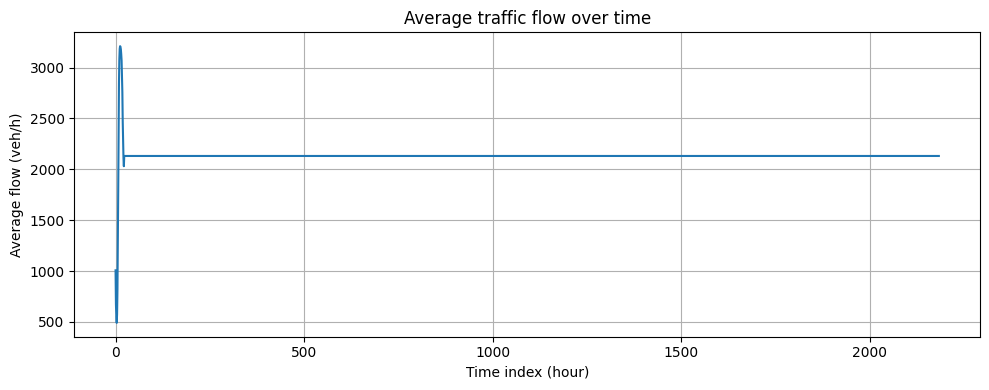

In [13]:
mean_flow_time = x_time[:, :, 0].mean(axis=1)

plt.figure(figsize=(10, 4))
plt.plot(mean_flow_time)
plt.xlabel("Time index (hour)")
plt.ylabel("Average flow (veh/h)")
plt.title("Average traffic flow over time")
plt.tight_layout()
plt.grid(True)
plt.show()


## 2: Hour-of-day profile

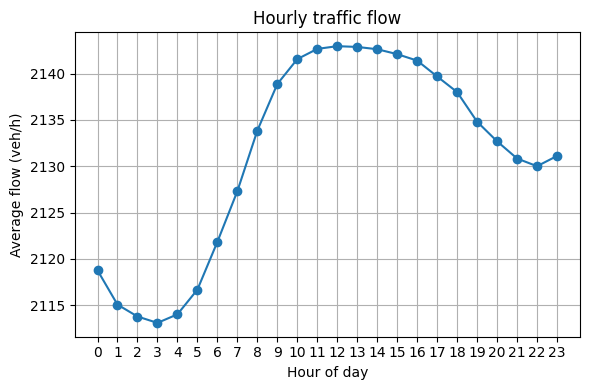

In [14]:
hours = np.arange(x_time.shape[0]) % 24
hourly_flow = np.zeros(24)

for h in range(24):
    hourly_flow[h] = x_time[hours == h, :, 0].mean()

plt.figure(figsize=(6, 4))
plt.plot(range(24), hourly_flow, marker="o")
plt.xlabel("Hour of day")
plt.ylabel("Average flow (veh/h)")
plt.title("Hourly traffic flow")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()


# 3. Flow vs Speed

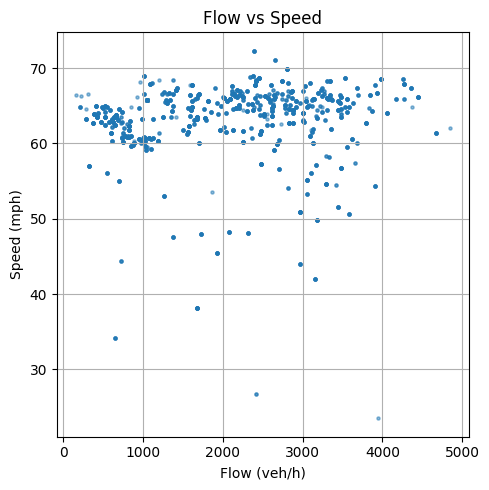

In [15]:
# 随机抽样，避免点太多
np.random.seed(0)
t_idx = np.random.choice(x_time.shape[0], 2000)
s_idx = np.random.choice(x_time.shape[1], 2000)

flow_sample = x_time[t_idx, s_idx, 0]
speed_sample = x_time[t_idx, s_idx, 2]

plt.figure(figsize=(5, 5))
plt.scatter(flow_sample, speed_sample, s=5, alpha=0.5)
plt.xlabel("Flow (veh/h)")
plt.ylabel("Speed (mph)")
plt.title("Flow vs Speed")
plt.tight_layout()
plt.grid(True)
plt.show()


# 4: Spatial correlation

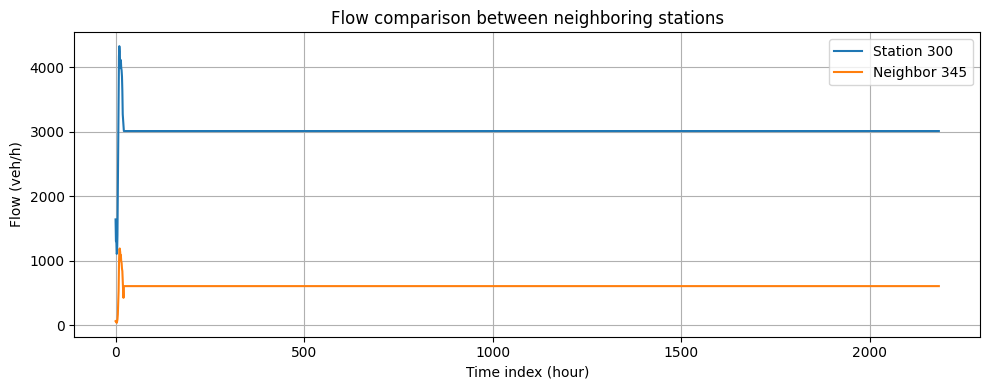

In [16]:
# 选一个站点和它的一个邻居
src = 300
neighbors = np.where(adj_matrix[src] == 1)[0]
dst = neighbors[0]

plt.figure(figsize=(10, 4))
plt.plot(x_time[:, src, 0], label=f"Station {src}")
plt.plot(x_time[:, dst, 0], label=f"Neighbor {dst}")
plt.xlabel("Time index (hour)")
plt.ylabel("Flow (veh/h)")
plt.title("Flow comparison between neighboring stations")
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()
